<a href="https://colab.research.google.com/github/tanishjain-tmj/-Predictive-Insight-Engine-Regressionmodels--ML/blob/main/Predictive_Insight_Engine_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Project: Predictive Insight Engine

#Part A: Theoritical Questions:

1. What are Supervised Learning Algorithms?

Ans. Supervised Learning is a Machine Learning technique in which a model is trained using labelled data (input and known output) to predict results for new data.

Examples: Linear Regression, Decision Tree, SVM, Random Forest.

2. Difference Between Regression and Classification

Ans. Regression	Classification
Predicts continuous values, Output is numerical,Example: House price prediction,Uses MAE, MSE, RMSE, R².

Classification Predicts categories or classes,
Output is categorical,	Example: Spam or Not Spam,	Uses Accuracy, Precision, Recall.

3. Explain Simple Linear Regression.

Ans. Simple Linear Regression is a supervised learning algorithm that predicts a continuous output using one independent variable.

Equation:

$$ Y=mX+c $$

Where:

Y = Predicted output
X = Input variable
m = Slope
c = Intercept

Example: Predicting house prices based on house area.


4. Assumptions of Linear Regression

Ans.Linearity: Relationship between input and output should be linear.

Independence: Observations and errors should be independent.

Homoscedasticity: Error variance should remain constant.

Normality: Residuals should be approximately normally distributed for standard statistical inference.

No Multicollinearity: Independent variables should not be highly correlated with each other.

5. What is Bias-Variance Trade-Off?

Ans.Bias-Variance Trade-Off refers to balancing bias and variance to achieve better model performance.

High Bias: Causes underfitting.
High Variance: Causes overfitting.
Balanced Bias and Variance: Produces better predictions on unseen data.

6. Explain Overfitting and Underfitting with Examples.

Ans.Overfitting:

Model learns training data too well, including noise.
Performs well on training data but poorly on testing data.
Example: A highly complex Polynomial Regression model.

Underfitting:

Model is too simple to learn important patterns.
Performs poorly on both training and testing data.
Example: Using Simple Linear Regression when the actual relationship is highly nonlinear.

#Part B: Practical

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#loading dataset
df= pd.read_excel("/content/RealEstate_HousePrice_Dataset_4200.xlsx")

In [3]:
df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


In [4]:
print("dataset information:")
df.info()

dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


In [5]:
print("dataset shape:\n",df.shape)

dataset shape:
 (4200, 12)


In [6]:
print("no. of duplicate data:\n",df.duplicated().sum())

no. of duplicate data:
 0


In [7]:
print("no. of missing values:\n",df.isnull().sum())

no. of missing values:
 house_id                0
area_sqft               0
bedrooms                0
bathrooms               0
location_score          0
age_years               0
distance_city_km        0
lot_size_sqft           0
has_garage              0
has_pool                0
renovation_years_ago    0
house_price_inr         0
dtype: int64


#Part B: Dataset understanding & preparation:

In [8]:
#independent and dependent variable:
x= df.drop(columns=['house_id','house_price_inr'])
y=df['house_price_inr']
print("Independent variable:",x.columns.to_list())
print("dependent variable:",y.name)

Independent variable: ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool', 'renovation_years_ago']
dependent variable: house_price_inr


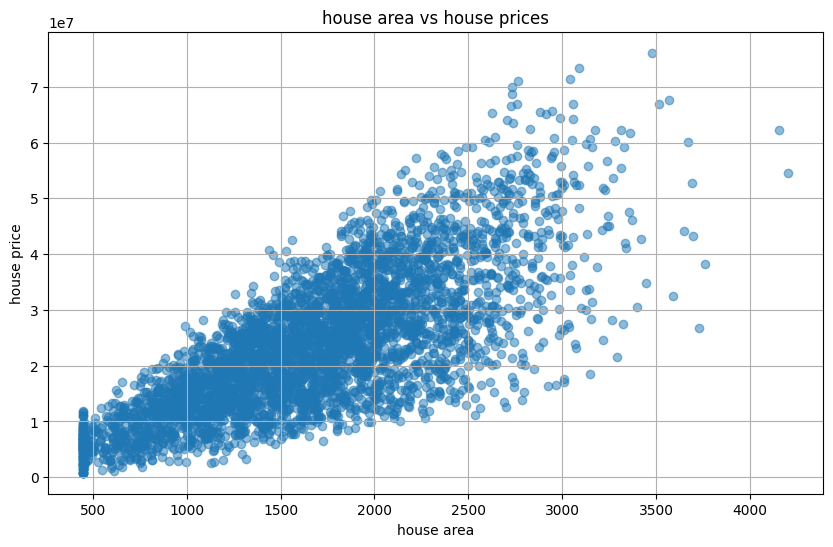

In [9]:
#visualization:
plt.figure(figsize=(10,6))
plt.scatter(df['area_sqft'],df['house_price_inr'],alpha=0.5)
plt.title("house area vs house prices")
plt.xlabel("house area")
plt.ylabel("house price")
plt.grid(True)
plt.show()

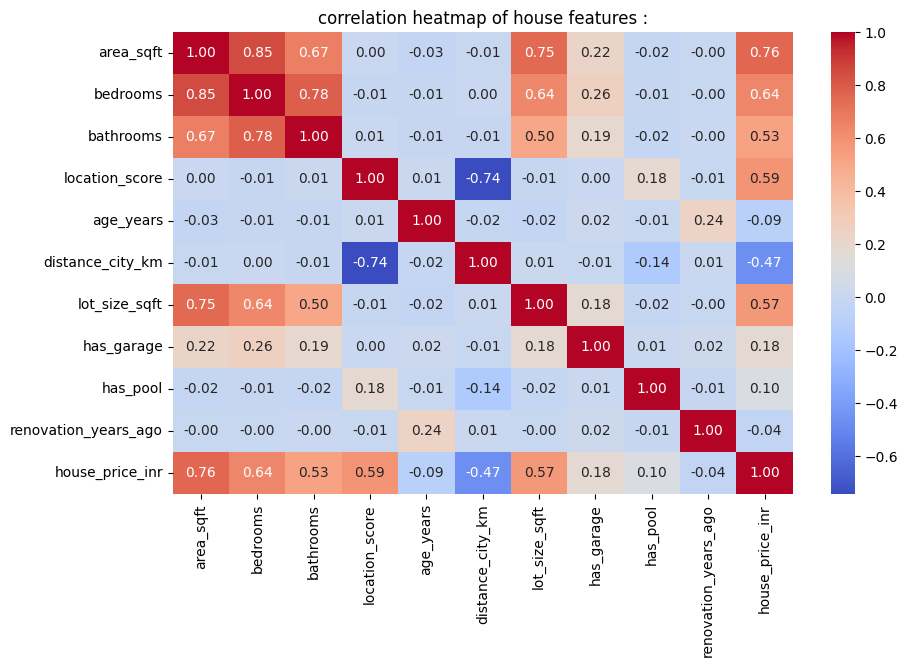

In [10]:
#correlation heatmap
plt.figure(figsize=(10,6))
correlation= df.drop(columns=['house_id']).corr()
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f')
plt.title("correlation heatmap of house features :")
plt.show()

In [11]:
#split the dataset :
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42)

print("xtrain shape",x_train.shape)
print("xtest shape",x_test.shape)
print("ytrain shape",y_train.shape)
print("ytest shape",y_test.shape)

xtrain shape (3360, 10)
xtest shape (840, 10)
ytrain shape (3360,)
ytest shape (840,)


#Part c: Simple linear regression

In [12]:
#making xtrain and xtest for SLR
x_simpletrain= x_train[['area_sqft']]
x_simpletest= x_test[['area_sqft']]
y_simpletrain= y_train
y_simpletest= y_test

In [13]:
from sklearn.linear_model import LinearRegression
lr= LinearRegression()
lr.fit(x_simpletrain,y_simpletrain)

LinearRegression()

In [14]:
slope= lr.coef_[0]
intercept= lr.intercept_
print("slope:",slope)
print("Intercept:",intercept)

slope: 14788.306111307542
Intercept: -1163519.1764186136


In [15]:
y_simplepred= lr.predict(x_simpletest)

comparison= pd.DataFrame({'Actual price': y_simpletest.values, 'Predicted price':y_simplepred})
print(comparison.head())

   Actual price  Predicted price
0      36890986     3.440236e+07
1      27836840     2.733355e+07
2      15321534     2.677159e+07
3      30812774     2.180272e+07
4      18194835     3.104541e+07


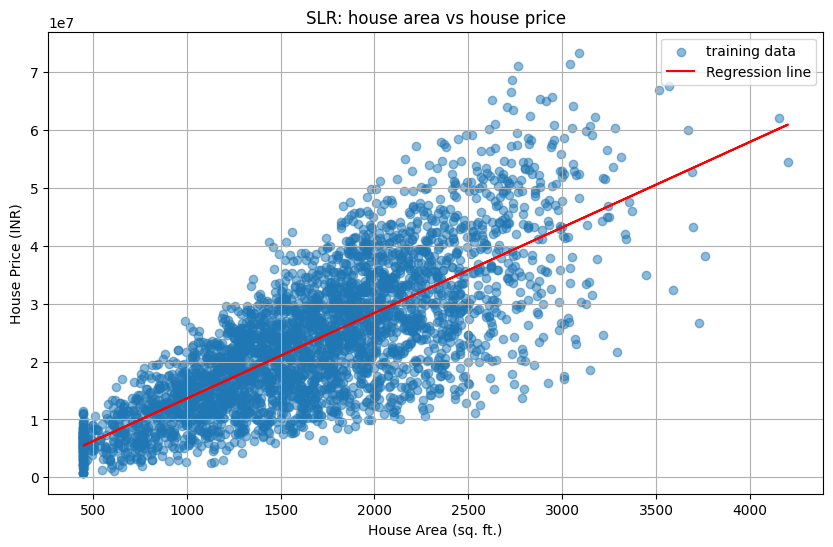

In [16]:
#plot the regression line:
plt.figure(figsize=(10,6))
plt.scatter(x_simpletrain['area_sqft'],y_simpletrain,alpha=0.5,label='training data')
plt.plot(x_simpletrain['area_sqft'],lr.predict(x_simpletrain),color='red',label='Regression line')
plt.title('SLR: house area vs house price')
plt.xlabel('House Area (sq. ft.)')
plt.ylabel('House Price (INR)')
plt.legend()
plt.grid(True)
plt.show()

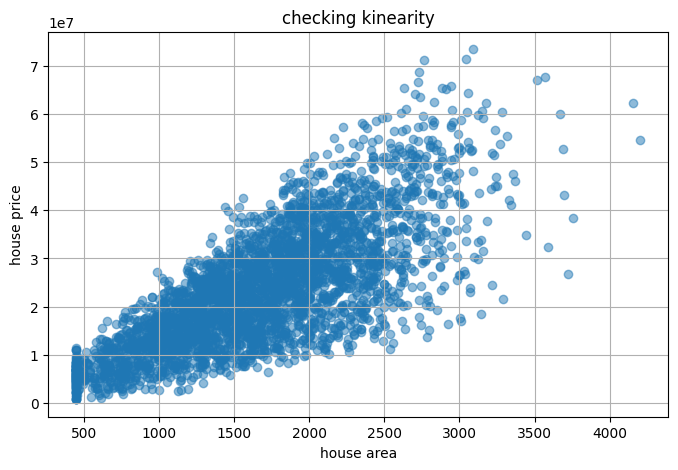

In [17]:
#checking linear regressuin assumptions:
#linearity:
plt.figure(figsize=(8,5))
plt.scatter(x_simpletrain['area_sqft'],y_simpletrain,alpha=0.5)
plt.title("checking kinearity")
plt.xlabel("house area")
plt.ylabel("house price")
plt.grid(True)
plt.show()

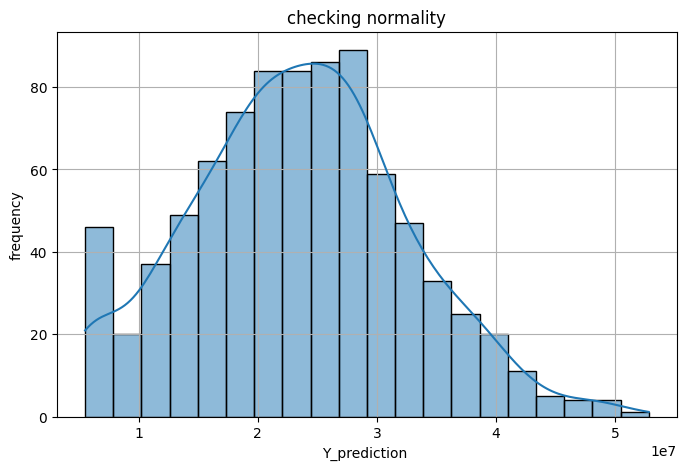

In [18]:
#normality:
plt.figure(figsize=(8,5))
sns.histplot(y_simplepred,bins=20,kde=True)
plt.title("checking normality")
plt.xlabel("Y_prediction ")
plt.ylabel("frequency")
plt.grid(True)
plt.show()

#part D : model evalution metrics:


In [19]:
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
mse= mean_squared_error(y_simpletest,y_simplepred)
mae= mean_absolute_error(y_simpletest,y_simplepred)
rmse=np.sqrt(mse)
r2= r2_score(y_simpletest,y_simplepred)

n=len(y_simpletest)
p=1
adjusted_r2= 1 -((1-r2)*(n-1)/ (n-p-1))

print("simple linear regression evaluation:")
print("mse:",mse)
print("mae:",mae)
print("rmse:",rmse)
print("r2 score:",r2)
print("adjusted r2 score:",adjusted_r2)

simple linear regression evaluation:
mse: 66989260021849.47
mae: 6294593.696131912
rmse: 8184696.696997969
r2 score: 0.5625199587991578
adjusted r2 score: 0.5619979062440257


In [20]:
#saving slr performance score:
simple_results={'model':'simple linear regression',
                'MSE':mse,
                'MAE':mae,
                'RMSE':rmse,
                'R2 Score':r2,
                'Adjusted R2 Score':adjusted_r2}
simple_results_df= pd.DataFrame([simple_results])
simple_results_df

,model,MSE,MAE,RMSE,R2 Score,Adjusted R2 Score
0,simple linear regression,6.698926e+13,6.294594e+06,8.184697e+06,0.56252,0.561998


#Part E: Multiple linear regression

In [21]:
x_multi_train= x_train.copy()
x_multi_test= x_test.copy()
y_multi_train= y_train.copy()
y_multi_test= y_test.copy()

In [22]:
from sklearn.linear_model import LinearRegression
multi_lr= LinearRegression()
multi_lr.fit(x_multi_train,y_multi_train)

LinearRegression()

In [23]:
y_multi_pred= multi_lr.predict(x_multi_test)

multi_comparison= pd.DataFrame({'actual price': y_multi_test.values,
                                'predicted price': y_multi_pred})
print(multi_comparison.head(10))

   actual price  predicted price
0      36890986     3.904170e+07
1      27836840     3.135621e+07
2      15321534     1.652577e+07
3      30812774     3.162615e+07
4      18194835     2.112133e+07
5      32960272     2.902569e+07
6      10714707     8.369081e+06
7      44555593     4.143504e+07
8      21525184     2.013180e+07
9      42840000     4.180599e+07


In [24]:
#checking accuray of multiple lr :
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
mse_multi= mean_squared_error(y_multi_test,y_multi_pred)
mae_multi= mean_absolute_error(y_multi_test,y_multi_pred)
rmse_multi=np.sqrt(mse_multi)
r2_multi= r2_score(y_multi_test,y_multi_pred)

n=len(y_multi_test)
p=x_multi_test.shape[1]
adjusted_r2_multi= 1 -((1-r2)*(n-1)/ (n-p-1))

print("simple linear regression evaluation:")
print("mse:",mse_multi)
print("mae:",mae_multi)
print("rmse:",rmse_multi)
print("r2 score:",r2_multi)
print("adjusted r2 score:",adjusted_r2_multi)

simple linear regression evaluation:
mse: 12592918884127.615
mae: 2604991.4061556906
rmse: 3548650.290480539
r2 score: 0.9177606877509898
adjusted r2 score: 0.5572427568546363


In [25]:
#comparing single and multiple linear regression:
comparison_results = pd.DataFrame([
 {'model':'simple linear regression',
  'MSE':mse,
  'MAE':mae,
  'RMSE':rmse,
  'R2 Score':r2,
  'Adjusted R2 Score':adjusted_r2},
 {'model':'multiple linaer regression',
  'MSE':mse_multi,
  'MAE':mae_multi,
  'RMSE':rmse_multi,
  'R2 Score':r2_multi,
  'Adjusted R2 Score':adjusted_r2_multi}])
print("comparison of slr and mlr:\n", comparison_results)

comparison of slr and mlr:
                         model           MSE           MAE          RMSE  \
0    simple linear regression  6.698926e+13  6.294594e+06  8.184697e+06   
1  multiple linaer regression  1.259292e+13  2.604991e+06  3.548650e+06   

   R2 Score  Adjusted R2 Score  
0  0.562520           0.561998  
1  0.917761           0.557243  


# multiple linear regression perform better:
because it contains multiple factors influencing house price . features such as location score, property age,etc which may provide predictive information beyond house area alone.


#part F: Polynomial regression

In [26]:
from sklearn.preprocessing import PolynomialFeatures

In [27]:
poly=PolynomialFeatures(degree=2)
x_poly_train= poly.fit_transform(x_train)
x_poly_test= poly.fit_transform(x_test)
y_poly_train= y_train.copy()
y_poly_test= y_test.copy()

lr2= LinearRegression()
lr2.fit(x_poly_train,y_poly_train)
y_poly_pred= lr2.predict(x_poly_test)

In [28]:
#checking accuray of polynomial lr :
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
mse_poly= mean_squared_error(y_poly_test,y_poly_pred)
mae_poly= mean_absolute_error(y_poly_test,y_poly_pred)
rmse_poly=np.sqrt(mse_poly)
r2_poly= r2_score(y_poly_test,y_poly_pred)

n=len(y_poly_test)
p=x_poly_test.shape[1]
adjusted_r2_poly= 1 -((1-r2)*(n-1)/ (n-p-1))

print("simple linear regression evaluation:")
print("mse:",mse_poly)
print("mae:",mae_poly)
print("rmse:",rmse_poly)
print("r2 score:",r2_poly)
print("adjusted r2 score:",adjusted_r2_poly)

simple linear regression evaluation:
mse: 5139490891574.132
mae: 1656922.8020122596
rmse: 2267044.527920467
r2 score: 0.9664360423407595
adjusted r2 score: 0.5251671997833033


In [29]:
#comparing linear and polynomial regression numerically:
comparison_results_2 = pd.DataFrame([
 {'model':'simple linear regression',
  'MSE':mse,
  'MAE':mae,
  'RMSE':rmse,
  'R2 Score':r2,
  'Adjusted R2 Score':adjusted_r2},
 {'model':'multiple linaer regression',
  'MSE':mse_multi,
  'MAE':mae_multi,
  'RMSE':rmse_multi,
  'R2 Score':r2_multi,
  'Adjusted R2 Score':adjusted_r2_multi},
 {'model':'polynomial linaer regression',
  'MSE':mse_poly,
  'MAE':mae_poly,
  'RMSE':rmse_poly,
  'R2 Score':r2_poly,
  'Adjusted R2 Score':adjusted_r2_poly}])
print("comparing linear and polynomial regression numerically:\n",comparison_results_2.head(10))

comparing linear and polynomial regression numerically:
                           model           MSE           MAE          RMSE  \
0      simple linear regression  6.698926e+13  6.294594e+06  8.184697e+06   
1    multiple linaer regression  1.259292e+13  2.604991e+06  3.548650e+06   
2  polynomial linaer regression  5.139491e+12  1.656923e+06  2.267045e+06   

   R2 Score  Adjusted R2 Score  
0  0.562520           0.561998  
1  0.917761           0.557243  
2  0.966436           0.525167  


In [31]:
#identify underfitting and overfitting :
y_polypredtrain=lr2.predict(x_poly_train)
y_polypredtest=lr2.predict(x_poly_test)

print("accuracy of train:",r2_score(y_poly_train,y_polypredtrain))
print("accuracy of test:",r2_score(y_poly_test,y_polypredtest))

train_r2 = r2_score(y_poly_train, y_polypredtrain)
test_r2 = r2_score(y_poly_test, y_polypredtest)

for train, test in [(train_r2, test_r2)]:

    if train < 0.5 and test < 0.5:
        print("Model is underfitting")

    elif train - test > 0.1:
        print("Model is overfitting")

    else:
        print("Model is performing well")

accuracy of train: 0.9684556843111441
accuracy of test: 0.9664360423407595
Model is performing well


#part g : gradient descent

Explain Gradient Descent Conceptually ?

Ans. Gradient Descent is an optimization algorithm used in Machine Learning to minimize the cost function (error) by updating the model's parameters repeatedly.

In simple words, Gradient Descent helps a machine learning model find the best values of weights and bias so that the difference between actual and predicted values becomes minimum.

In [32]:
#scaling features:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
x_sca_train= scaler.fit_transform(x_train)
x_sca_test= scaler.transform(x_test)

In [35]:
#SGD regression:
from sklearn.linear_model import SGDRegressor
sgd= SGDRegressor(max_iter=1000,learning_rate='constant',random_state=42)
sgd.fit(x_sca_train,y_train)
y_sgd_pred= sgd.predict(x_sca_test)


In [36]:
mae_sgd= mean_absolute_error(y_test,y_sgd_pred)
print("Mean absolute error:",mae_sgd)

Mean absolute error: 2635779.115474116


Part H : Bias-varience and model diagonstics

In [42]:
#analyze bias and varience:
#simple linear regression
print("Simple linear regression:")
rmse_train_linear= np.sqrt(mean_squared_error(y_simpletrain,lr.predict(x_simpletrain)))
print("Bias:", rmse_train_linear)
rmse_test_linear= np.sqrt(mean_squared_error(y_simpletest,lr.predict(x_simpletest)))
print("variance:",rmse_test_linear,"\n")

print("multiple linear regression:")
rmse_train_mult= np.sqrt(mean_squared_error(y_multi_train,multi_lr.predict(x_multi_train)))
print("Bias:", rmse_train_mult)
rmse_test_mult= np.sqrt(mean_squared_error(y_multi_test,multi_lr.predict(x_multi_test)))
print("variance:",rmse_test_mult,"\n")

print("Polynomial regression:")
rmse_train_poly= np.sqrt(mean_squared_error(y_poly_train,lr2.predict(x_poly_train)))
print("Bias:", rmse_train_poly)
rmse_test_poly= np.sqrt(mean_squared_error(y_poly_test,lr2.predict(x_poly_test)))
print("variance:",rmse_test_poly,"\n")


Simple linear regression:
Bias: 8104428.03525333
variance: 8184696.696997969 

multiple linear regression:
Bias: 3400098.875994466
variance: 3548650.290480539 

Polynomial regression:
Bias: 2200985.0871174033
variance: 2267044.527920467 



Q.Explain how Model Complexity Affects Prediction Error

Ans. Model complexity refers to how complicated a machine learning model is and how many patterns or relationships it can learn from data.

Low complexity: High bias, low variance, and may cause underfitting.

Moderate complexity: Balances bias and variance, giving better predictions.

High complexity: Low bias, high variance, and may cause overfitting.

As model complexity increases, bias generally decreases and variance increases.

Q. identify which model best balances bias and variance

Ans. Best Model: Polynomial Regression (Degree 2).

Reason: Polynomial Regression has the lowest bias and variance among the three models. Therefore, based on these values, it provides the best bias-variance balance.


Part I: Final Analysis and report

Q Summary:

Ans.

1. Best-performing Model: Polynomial Regression (Degree 2) performed best based on our calculated bias and variance values, as it captured nonlinear relationships in house prices.

2. Impact of Gradient Descent: Gradient Descent helped optimize model parameters by minimizing prediction errors. Batch, Stochastic, and Mini-Batch methods offer different convergence speeds and behaviors.

3. Overfitting/Underfitting: Simple Linear Regression may underfit due to limited input features, while Polynomial Regression can capture complex patterns but may overfit.

4. Practical Business Interpretation: The model can help estimate house prices based on property features, supporting buyers, sellers, and real estate businesses in making better pricing decisions.